# Experiment ladder: sums of sinusoids under increasing distortion

The regimes are the same as in `experiment_sines.ipynb`: K = 4 regimes, each a sum of three sinusoids with its own frequencies and equal amplitudes, so only the spectrum changes between regimes. This notebook repeats that experiment at one rung of a cumulative distortion ladder (each level keeps everything below it):

| level | adds | channels |
|---|---|---|
| L0 | pure sines, white noise σ = 0.3 (the original experiment) | 1 |
| L1 | each sine passed through `pointwise triangle`: triangle waves (odd harmonics at 3f, 5f, …) | 1 |
| L2 | stronger white noise, σ = 1.0 (SNR ≈ 1) | 1 |
| L3 | the three triangle waves are no longer summed: a random up-projection mixes them into D = 8 channels, noise σ = 1 per channel | 8 |
| L4 | autocorrelation: two regime-independent slow AR(1) nuisances (φ = 0.95) mixed in, per-channel low-pass sensor dynamics, coloured AR noise (correlation time 16) | 8 |
| L5 | nonlinear and sensor distortions: invertible coupling layers (nonlinear mixing), gain drift, stochastic volatility, baseline wander, outliers, saturation, slight time warp | 8 |

Set the level with the environment variable `CPBENCH_LEVEL` (or edit `LEVEL` below).

**Protocol** (as in the original experiment):
1. Fit every available feature learner on fresh samples: raw-window baselines, the clean-signal spectral oracle, all LeJEPA variants, AE, VAE, β-VAE, `ae_pred` / `vae_pred` (linear predictor in latent space), CPC, TS2Vec, and an untrained `jepa_shared` control.
2. Run every registered detector on each learner's test features (clustering: GMM, HMM, AR-HMM, temporal excess; change points: contrast, MMD, BOCPD, DMD error, CPDMD).
3. Score at sample level: clustering accuracy (chance 0.25), change-point AP / F1 / covering.

All levels share one cache directory (datasets are identified by construction), and each level writes `cpbench_results/sines_L<level>.csv`. The last section compares every level found on disk.

**Cost.** About 1.5 h per level locally (12 trained networks × 3000 steps on MPS plus the detectors). `CPBENCH_QUICK=1` is a plumbing check whose numbers mean nothing.

In [1]:
import os, json, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from cpbench import Benchmark, make_learner, make_detector, viz
from cpbench.data import Dataset
from cpbench.features import LEARNERS
from cpbench.detectors import DETECTORS
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110, "font.size": 9})
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 80)
warnings.filterwarnings("ignore", message="FastICA did not converge")

QUICK = os.environ.get("CPBENCH_QUICK") == "1"     # ✏️ True: plumbing check only (20 steps, tiny splits)
LEVEL = int(os.environ.get("CPBENCH_LEVEL", 1))    # ✏️ distortion level 0-5
RUNS = "cpbench_runs_sines" + ("_quick" if QUICK else "")
OUT = f"cpbench_results/sines_L{LEVEL}" + ("_quick" if QUICK else "") + ".csv"
print("QUICK" if QUICK else "full run", f"level {LEVEL} ->", OUT)

full run level 1 -> cpbench_results/sines_L1.csv


## 1. Dataset

`FREQS[k]` lists the three frequencies (cycles per sample) of regime k; each is a pure sine of amplitude 1 (`oscillator` with `damp=1, sigma=0`) whose frequency follows the regime. `dataset(level)` builds the cumulative ladder from the table above; standardisation per channel is applied at the end.

With W = 64 the spectral resolution is 1/64 ≈ 0.016 cycles per sample. A segment lasts 640 samples on average, about 10 windows.

In [2]:
# ✏️ the ladder
FREQS = [[0.020, 0.070, 0.150], [0.035, 0.090, 0.200], [0.050, 0.110, 0.170], [0.030, 0.130, 0.240]]
LEVELS = ["L0 sines", "L1 triangle", "L2 + noise", "L3 + up-projection", "L4 + autocorrelation", "L5 + nonlinear sensor"]

def dataset(level, quick=False):
    waves = [dict(type="pointwise", fn="triangle", amplitude=1.0)] if level >= 1 else []
    summed = level < 3
    signal = dict(type="composite",
                  sources=[dict(type="oscillator", d=3, freq=FREQS, damp=1.0, sigma=0.0, amplitude=1.0)],
                  transforms=waves + ([dict(type="linear", weights=[[1, 1, 1]])] if summed else []))
    sources = [signal]
    if level >= 4:
        sources.append(dict(type="ar", d=2, phi=0.95))                       # regime-independent slow nuisances
    tf = []
    if level >= 3:
        tf.append(dict(type="project", D=8))
    if level >= 5:
        tf.append(dict(type="couplings", n=2, strength=0.5))
    if level >= 4:
        tf.append(dict(type="lowpass", max_alpha=0.6))
    tf.append(dict(type="noise", sigma=0.3 if level < 2 else 1.0))
    if level >= 4:
        tf.append(dict(type="noise", sigma=0.7, timescale=16))
    if level >= 5:
        tf += [dict(type="gain_drift", scale=0.25, timescale=1600), dict(type="volatility", scale=0.3, timescale=640),
               dict(type="wander", scale=0.5, timescale=6400), dict(type="outliers", rate=0.002, size=5.0),
               dict(type="saturate", level=3.0), dict(type="time_warp", strength=0.1, timescale=256)]
    return dict(regime=dict(type="markov", K=len(FREQS), dwell=640), sources=sources, transforms=tf, seed=0,
                splits=dict(test=[2, 4000], val=[2, 4000]) if quick else dict(test=[8, 32000], val=[4, 16000]))

DATASET = dataset(LEVEL, QUICK)
W, GAP = 64, 64                         # ✏️ window and context-target gap (samples)
ds = Dataset(DATASET)
data = ds.test_set()
print(LEVELS[LEVEL]); print(ds.info.id)
print(f"K={ds.K}, D={ds.D}, test split {data['obs'].shape}")

L1 triangle
markov(dwell=640)|[oscillator(amplitude=1,d=3,damp=1,freq=[[0.02,0.07,0.15],[0.035,0.09,0.2],[0.05,0.11,0.17],[0.03,0.13,0.24]],sigma=0)|pointwise>linear(weights=[[1,1,1]])]|-|noise(sigma=0.3)#d8b0c25a
K=4, D=1, test split (8, 32000, 1)


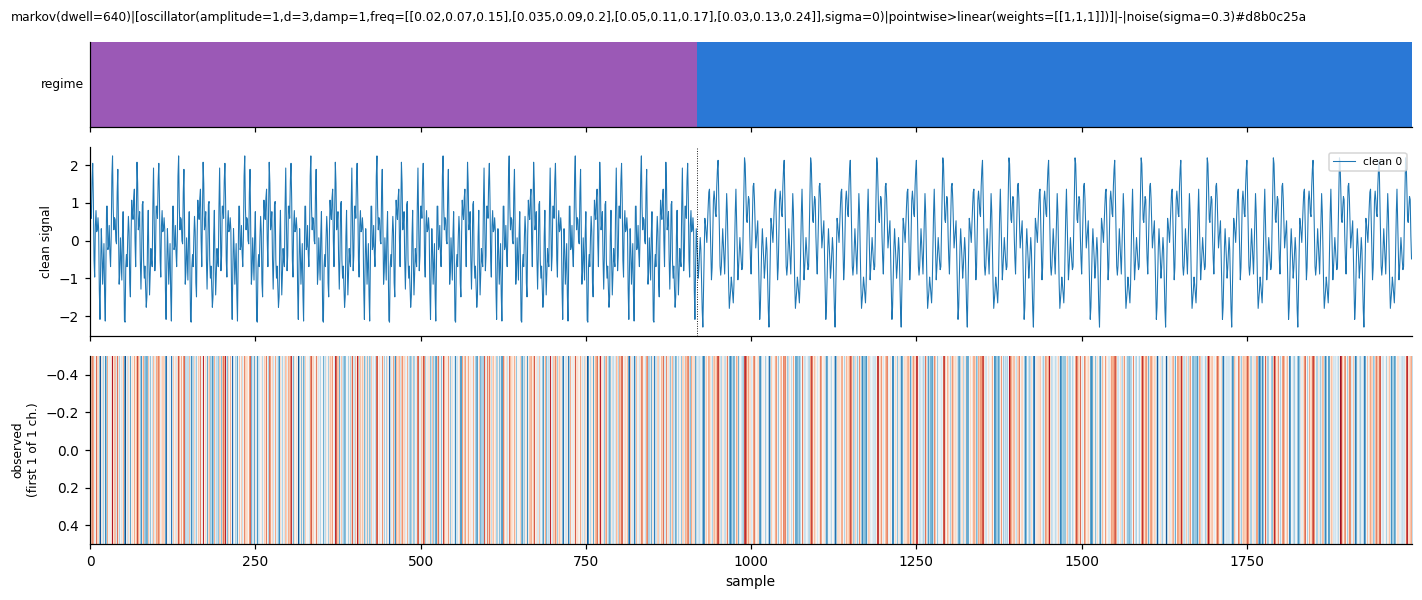

In [3]:
viz.plot_dataset(ds, data, series=0, n=2000)

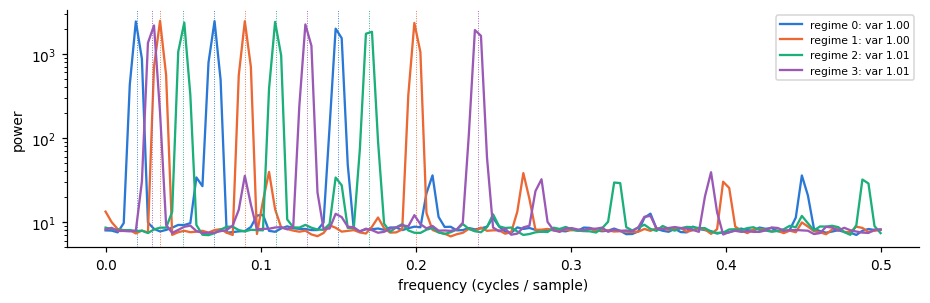

In [4]:
# check: per-regime variance and power spectrum of channel 0 of the test split (only the spectrum should differ;
# at L5 slow gain / volatility make short-sample variances noisy)
x, S, L = data["obs"][..., 0], data["S_s"], 256
f = np.fft.rfftfreq(L)
fig, ax = plt.subplots(figsize=(10, 2.8))
for k in range(ds.K):
    segs = [x[r, t:t + L] for r in range(len(x)) for t in range(0, x.shape[1] - L, L // 2) if (S[r, t:t + L] == k).all()]
    if not segs:
        continue
    P = np.mean([np.abs(np.fft.rfft(s * np.hanning(L))) ** 2 for s in segs], 0)
    ax.semilogy(f, P, color=viz.COLORS[k], label=f"regime {k}: var {np.var(np.concatenate(segs)):.2f}")
    for fr in FREQS[k]:
        ax.axvline(fr, color=viz.COLORS[k], lw=0.6, ls=":")
ax.set_xlabel("frequency (cycles / sample)"); ax.set_ylabel("power"); ax.legend(fontsize=7); plt.show()

## 2. Feature learners and detectors

All registered feature learners are used, except the generic bases (`raw`, `oracle`, `jepa`), which their presets already cover, `oracle_hidden`, which needs a hidden state this dataset does not have, and on a univariate series `raw_lagcov`, which measures which channel leads another.
- Every learner uses the same window W.
- The learners trained on (context, target) pairs also get the gap.
- `oracle_clean` computes the window *spectrum* of the noise-free sum of sines: a ceiling, not a competitor. Its default statistic (mean, variance, …) is identical in every regime here by construction.
- **Control:** `jepa_shared` with `steps=0`, a randomly initialised encoder. A random convolutional encoder already separates spectra to some degree, so a trained learner only counts if it beats this control.

Every registered detector runs with its default parameters, which the ✏️ cell can override. The defaults suit sequences of window features (T = 500 windows per test series here).

In [5]:
SKIP = {"raw", "oracle", "jepa", "oracle_hidden"}
if ds.D == 1:
    SKIP.add("raw_lagcov")              # lead-lag between channels: undefined on one channel
print("feature learners:", [n for n in LEARNERS.available() if n not in SKIP])
print("detectors:       ", DETECTORS.available())

feature learners: ['ae', 'ae_pred', 'bvae4', 'cpc', 'jepa_mlp_separate', 'jepa_mlp_shared', 'jepa_separate', 'jepa_separate_full', 'jepa_shared', 'oracle_clean', 'raw_bispec', 'raw_coskew', 'raw_cov', 'raw_flat', 'raw_mean', 'raw_spectra', 'raw_stats', 'ts2vec', 'vae', 'vae_pred']
detectors:        ['arhmm', 'bocpd', 'contrast', 'cpdmd', 'dmd_error', 'gmm', 'hmm', 'mmd', 'temporal_excess']


In [6]:
# ✏️ training settings (workers / device / logging do not change the result)
STEPS = 20 if QUICK else 3000
TRAIN = dict(steps=STEPS, batch=128, workers=0 if QUICK else 1, eval_every=max(STEPS // 4, 5), warmup=min(1000, STEPS))

def learner(name, **extra):
    defaults = LEARNERS.defaults(name)
    p = dict(window=W)
    if "gap" in defaults:
        p["gap"] = GAP
    if "steps" in defaults:
        p.update(TRAIN)
    if name == "oracle_clean":
        p["feature"] = "spectra"         # the regimes differ only in their spectrum
    return make_learner(name, **{**p, **extra})

FEATURES = [learner(n) for n in LEARNERS.available() if n not in SKIP]
FEATURES.append(learner("jepa_shared", steps=0))   # control: untrained (random) encoder
FIXED = [f for f in FEATURES if not f.trainable]
LEARNT = [f for f in FEATURES if f.trainable]

# ✏️ detectors: every registered one, with optional parameter overrides
OVERRIDES = {}                          # e.g. {"bocpd": dict(hazard=0.1), "cpdmd": dict(w=40, d=10, r=4)}
DETS = [dict(type=n, **OVERRIDES.get(n, {})) for n in DETECTORS.available()]
print(len(FIXED), "fixed and", len(LEARNT), "trained feature learners;", len(DETS), "detectors")

8 fixed and 13 trained feature learners; 9 detectors


## 3. Fit, extract features, detect

The fixed learners run first. Each trained learner is then fitted, or loaded if `RUNS` already holds it, and every detector runs on its features. Results go to `OUT` after each learner, so an interrupted run keeps what it finished.

In [7]:
bench = Benchmark(ds, detectors=DETS, out=RUNS, log=lambda *a: None)
results = []
for f in FIXED + LEARNT:
    results.append(bench.run(f))
    pd.concat(results, ignore_index=True).to_csv(OUT, index=False)
    r = results[-1]; r = r[(r.view == "features") & r.metric.isin(["acc", "cp_ap"])]
    print(f"{f.label():<40}", "  ".join(f"{m} max {r[r.metric == m].value.max():.2f}" for m in ("acc", "cp_ap")))
res = pd.concat(results, ignore_index=True)

oracle_clean(window=64, feature=spectra) acc max 0.97  cp_ap max 0.79
raw_bispec(window=64)                    acc max 0.97  cp_ap max 0.80
raw_coskew(window=64)                    acc max 0.45  cp_ap max 0.06
raw_cov(window=64)                       acc max 0.27  cp_ap max 0.04
raw_flat(window=64)                      acc max 0.97  cp_ap max 0.86
raw_mean(window=64)                      acc max 0.46  cp_ap max 0.07
raw_spectra(window=64)                   acc max 0.97  cp_ap max 0.79
raw_stats(window=64)                     acc max 0.64  cp_ap max 0.37
ae(window=64, gap=64, steps=3000, batch=128) acc max 0.97  cp_ap max 0.85
ae_pred(window=64, gap=64, steps=3000, batch=128) acc max 0.96  cp_ap max 0.56
bvae4(window=64, gap=64, steps=3000, batch=128) acc max 0.96  cp_ap max 0.58
cpc(window=64, gap=64, steps=3000, batch=128) acc max 0.97  cp_ap max 0.80
jepa_mlp_separate(window=64, gap=64, steps=3000, batch=128) acc max 0.97  cp_ap max 0.83
jepa_mlp_shared(window=64, gap=64, steps=3000,

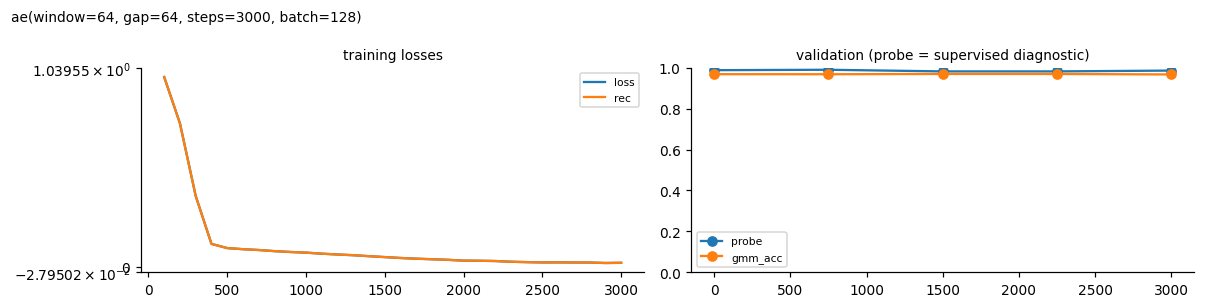

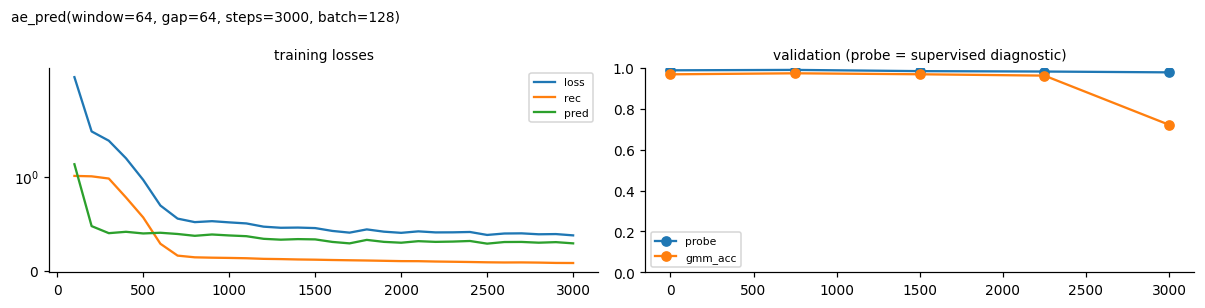

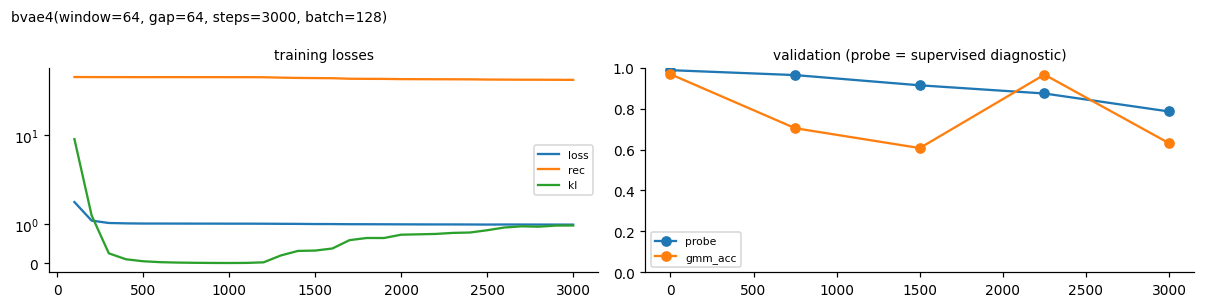

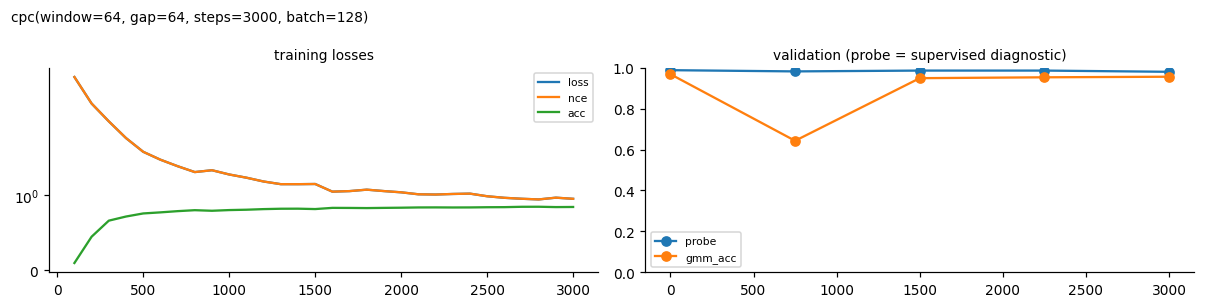

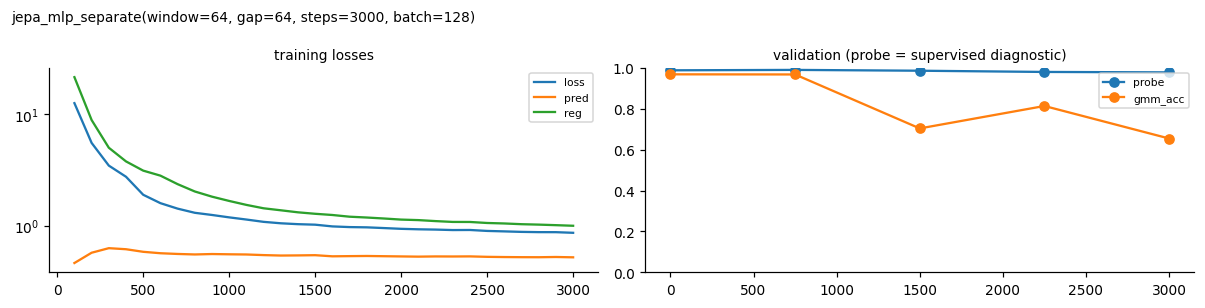

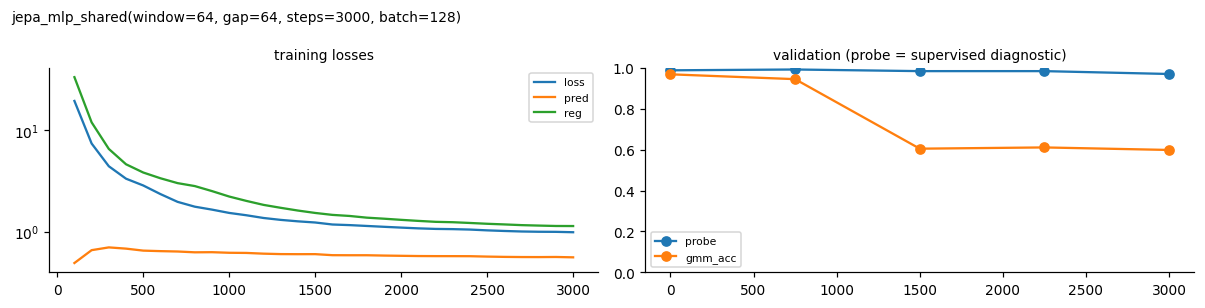

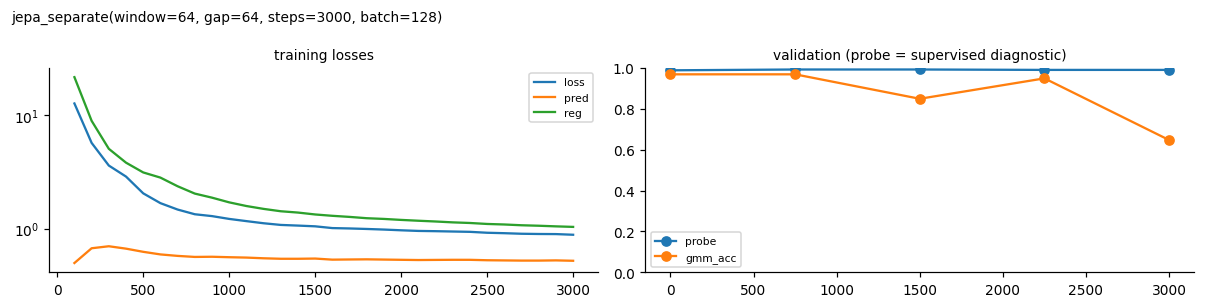

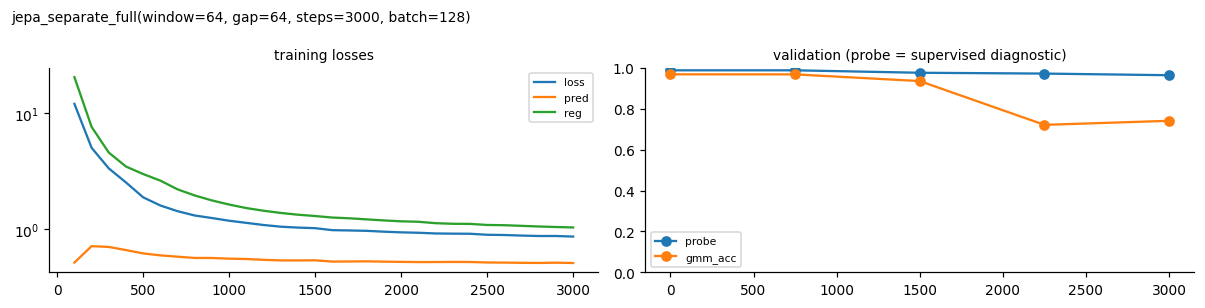

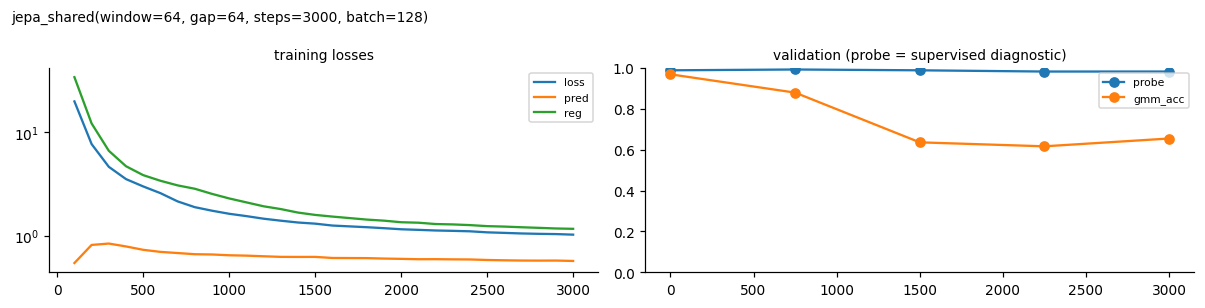

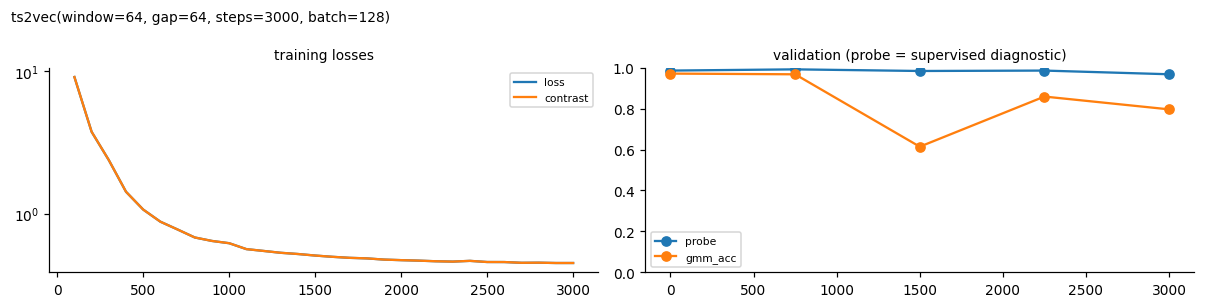

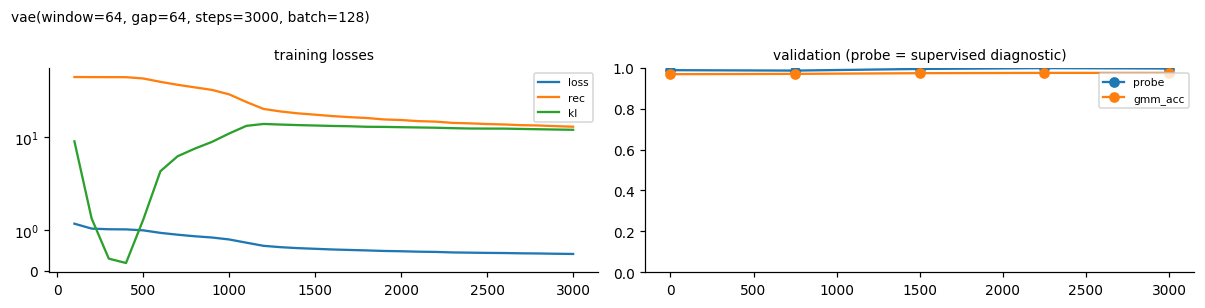

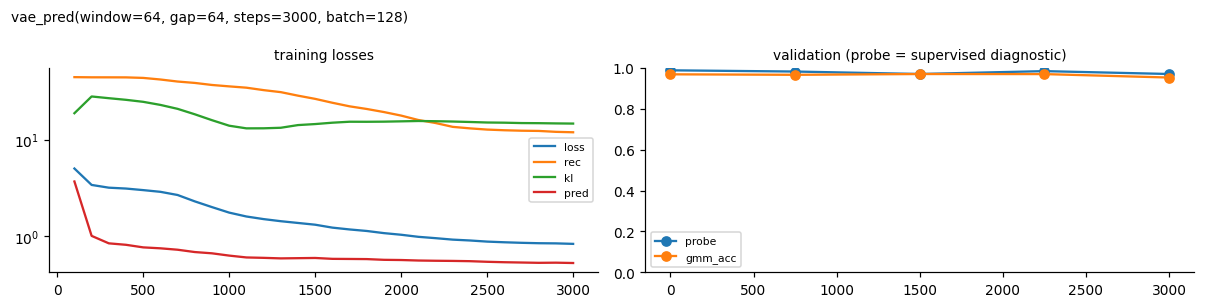

no training log (fixed feature learner?)


In [8]:
# training curves of the trained learners (losses; validation probe and GMM accuracy)
for f in LEARNT:
    viz.plot_training(bench.run_dir(f), title=f.label())

## 4. Results

The heatmaps show every feature learner × detector:
- `acc`: sample-level clustering accuracy after the best label permutation (chance 0.25);
- `cp_ap`: change-point average precision;
- `cp_f1`: F1 at the default threshold, or at the detector's own alarms (CPDMD).

Change-point detectors have no `acc`. Rows are the feature learners and columns the detectors.

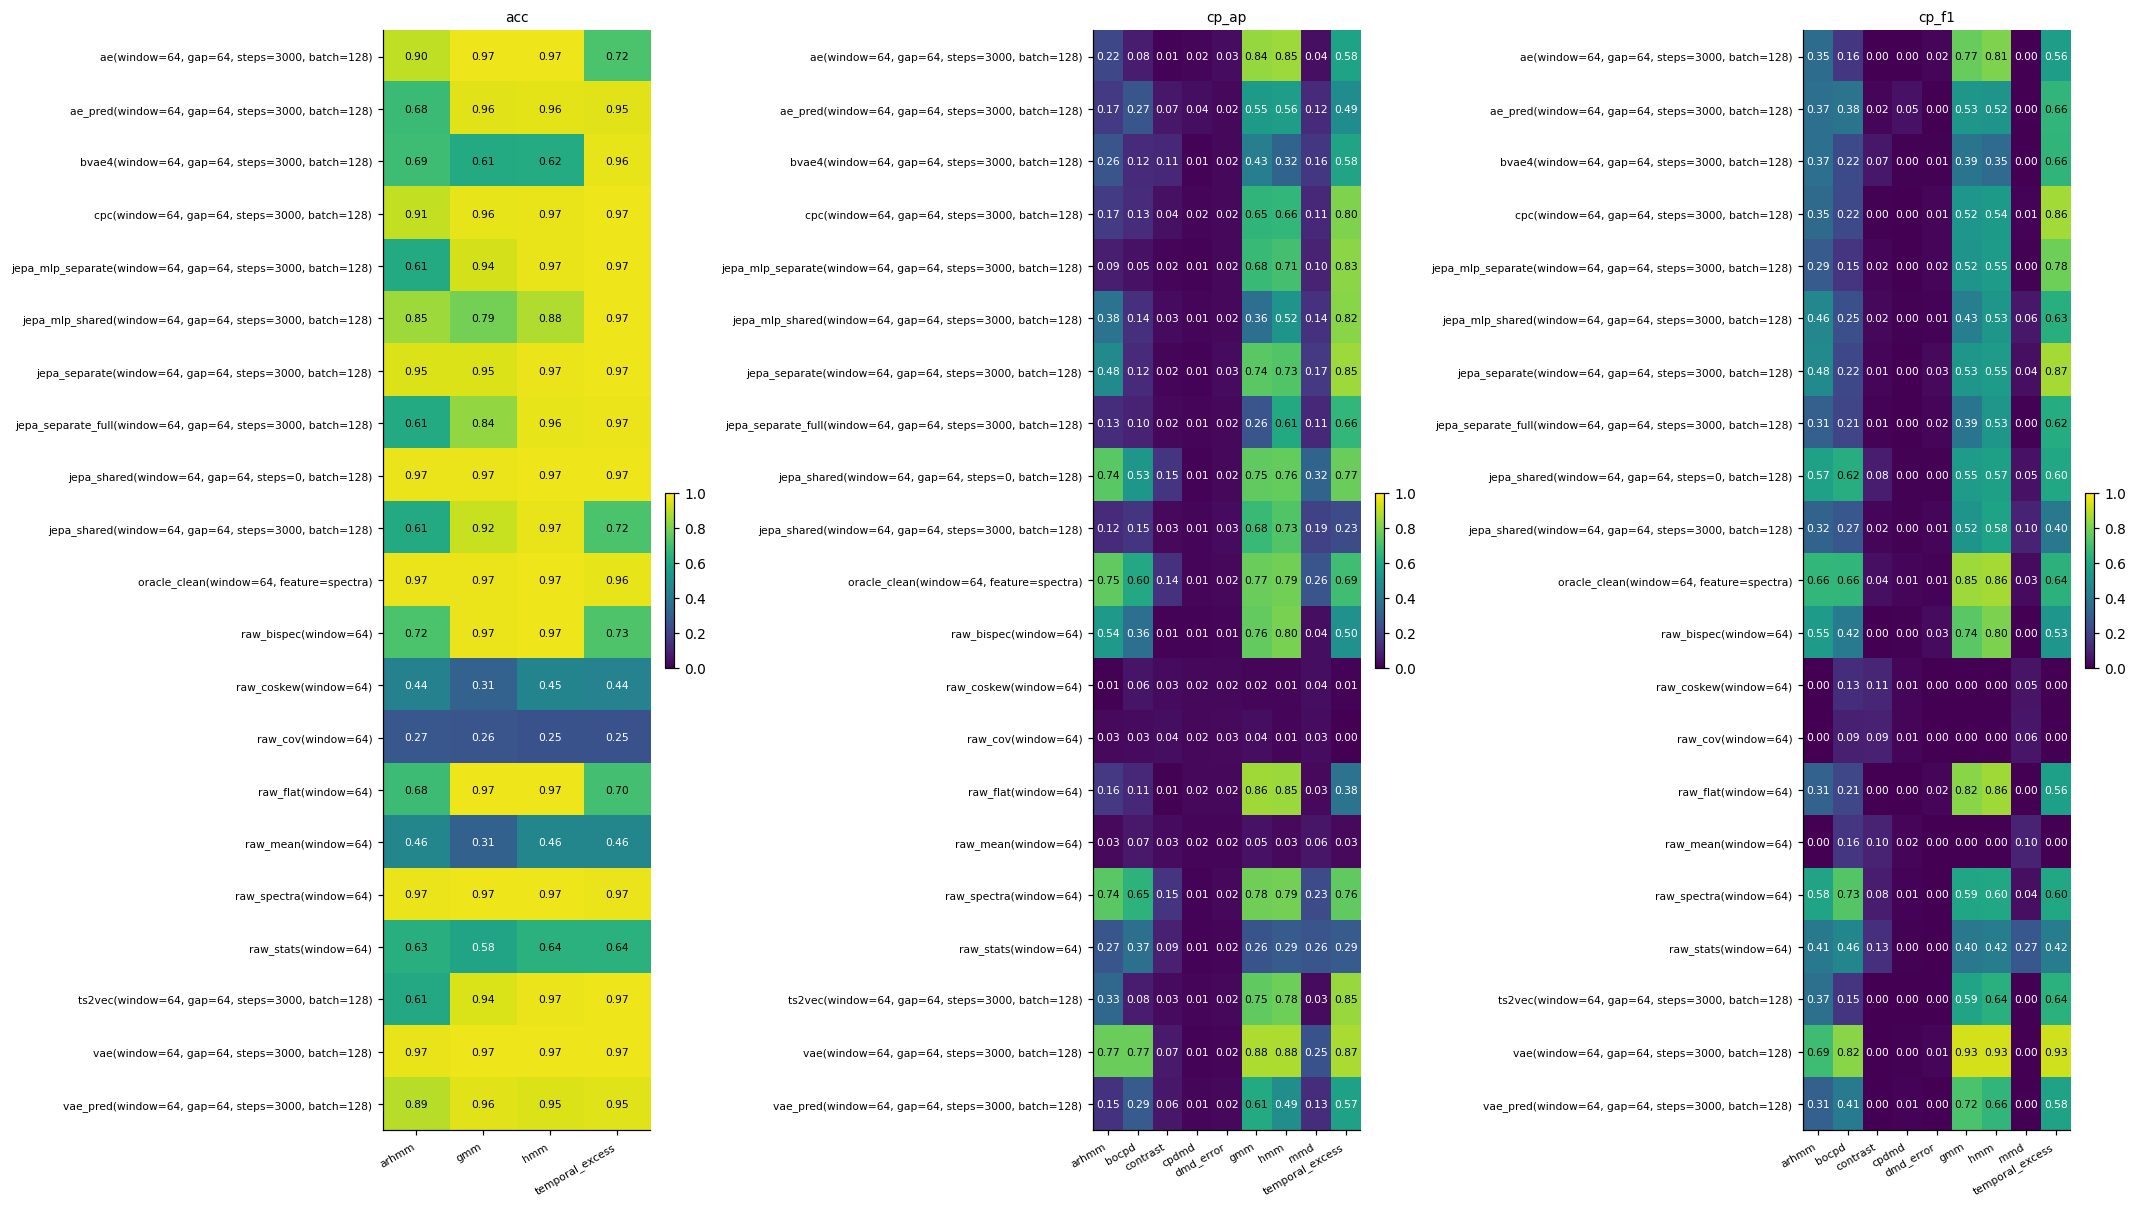

In [9]:
viz.plot_results(res, metrics=("acc", "cp_ap", "cp_f1"))

In [10]:
# best detector per feature learner (clustering accuracy, change-point AP), plus the supervised probe (diagnostic)
f_ = res[res.view == "features"]
best = pd.DataFrame({
    "acc (best clustering detector)": f_[f_.metric == "acc"].groupby("features_label").value.max(),
    "cp_ap (best detector)": f_[f_.metric == "cp_ap"].groupby("features_label").value.max(),
    "linear probe (supervised)": f_[(f_.detector == "probe") & (f_.metric == "probe_linear")].groupby("features_label").value.max(),
})
best.sort_values("acc (best clustering detector)", ascending=False).round(3)

,acc (best clustering detector),cp_ap (best detector),linear probe (supervised)
features_label,,,
"vae(window=64, gap=64, steps=3000, batch=128)",0.975,0.878,0.994
"jepa_separate(window=64, gap=64, steps=3000, batch=128)",0.974,0.853,0.989
raw_flat(window=64),0.974,0.859,0.283
raw_bispec(window=64),0.974,0.797,0.334
"ts2vec(window=64, gap=64, steps=3000, batch=128)",0.974,0.847,0.984
"oracle_clean(window=64, feature=spectra)",0.974,0.789,0.992
"ae(window=64, gap=64, steps=3000, batch=128)",0.973,0.855,0.983
"jepa_shared(window=64, gap=64, steps=0, batch=128)",0.973,0.771,0.987
raw_spectra(window=64),0.973,0.792,0.990


In [11]:
# full tables
for m in ("acc", "cp_ap", "cp_f1", "cp_covering"):
    t = f_[(f_.metric == m) & (f_.detector != "probe")].pivot_table(index="features_label", columns="detector_label", values="value")
    if len(t):
        print(m); display(t.round(3))

acc


detector_label,arhmm,gmm,hmm,temporal_excess
features_label,,,,
"ae(window=64, gap=64, steps=3000, batch=128)",0.903,0.973,0.973,0.716
"ae_pred(window=64, gap=64, steps=3000, batch=128)",0.683,0.955,0.961,0.955
"bvae4(window=64, gap=64, steps=3000, batch=128)",0.691,0.612,0.615,0.964
"cpc(window=64, gap=64, steps=3000, batch=128)",0.908,0.962,0.966,0.973
"jepa_mlp_separate(window=64, gap=64, steps=3000, batch=128)",0.610,0.937,0.966,0.973
"jepa_mlp_shared(window=64, gap=64, steps=3000, batch=128)",0.853,0.793,0.883,0.973
"jepa_separate(window=64, gap=64, steps=3000, batch=128)",0.946,0.946,0.969,0.974
"jepa_separate_full(window=64, gap=64, steps=3000, batch=128)",0.612,0.838,0.965,0.970
"jepa_shared(window=64, gap=64, steps=0, batch=128)",0.971,0.972,0.973,0.973


cp_ap


detector_label,arhmm,bocpd,contrast,cpdmd,dmd_error,gmm,hmm,mmd,temporal_excess
features_label,,,,,,,,,
"ae(window=64, gap=64, steps=3000, batch=128)",0.219,0.077,0.010,0.019,0.032,0.843,0.855,0.043,0.579
"ae_pred(window=64, gap=64, steps=3000, batch=128)",0.170,0.266,0.066,0.037,0.023,0.545,0.559,0.123,0.486
"bvae4(window=64, gap=64, steps=3000, batch=128)",0.263,0.122,0.113,0.011,0.023,0.426,0.323,0.163,0.583
"cpc(window=64, gap=64, steps=3000, batch=128)",0.173,0.127,0.044,0.015,0.023,0.653,0.663,0.111,0.805
"jepa_mlp_separate(window=64, gap=64, steps=3000, batch=128)",0.085,0.050,0.019,0.012,0.020,0.678,0.707,0.097,0.826
"jepa_mlp_shared(window=64, gap=64, steps=3000, batch=128)",0.380,0.138,0.031,0.014,0.023,0.364,0.519,0.141,0.824
"jepa_separate(window=64, gap=64, steps=3000, batch=128)",0.476,0.123,0.018,0.011,0.028,0.743,0.728,0.168,0.853
"jepa_separate_full(window=64, gap=64, steps=3000, batch=128)",0.132,0.097,0.022,0.012,0.023,0.263,0.607,0.112,0.662
"jepa_shared(window=64, gap=64, steps=0, batch=128)",0.743,0.530,0.148,0.010,0.022,0.755,0.763,0.323,0.771


cp_f1


detector_label,arhmm,bocpd,contrast,cpdmd,dmd_error,gmm,hmm,mmd,temporal_excess
features_label,,,,,,,,,
"ae(window=64, gap=64, steps=3000, batch=128)",0.352,0.160,0.000,0.000,0.016,0.768,0.806,0.000,0.562
"ae_pred(window=64, gap=64, steps=3000, batch=128)",0.366,0.384,0.019,0.050,0.000,0.530,0.517,0.000,0.659
"bvae4(window=64, gap=64, steps=3000, batch=128)",0.365,0.225,0.066,0.005,0.008,0.390,0.351,0.000,0.655
"cpc(window=64, gap=64, steps=3000, batch=128)",0.345,0.221,0.005,0.000,0.013,0.525,0.545,0.010,0.863
"jepa_mlp_separate(window=64, gap=64, steps=3000, batch=128)",0.287,0.153,0.019,0.000,0.017,0.519,0.554,0.005,0.779
"jepa_mlp_shared(window=64, gap=64, steps=3000, batch=128)",0.465,0.246,0.022,0.005,0.009,0.432,0.529,0.064,0.630
"jepa_separate(window=64, gap=64, steps=3000, batch=128)",0.480,0.218,0.013,0.000,0.026,0.531,0.548,0.042,0.865
"jepa_separate_full(window=64, gap=64, steps=3000, batch=128)",0.308,0.209,0.008,0.000,0.018,0.389,0.528,0.005,0.618
"jepa_shared(window=64, gap=64, steps=0, batch=128)",0.572,0.624,0.081,0.005,0.004,0.550,0.567,0.051,0.597


cp_covering


detector_label,arhmm,bocpd,contrast,cpdmd,dmd_error,gmm,hmm,mmd,temporal_excess
features_label,,,,,,,,,
"ae(window=64, gap=64, steps=3000, batch=128)",0.666,0.454,0.282,0.061,0.259,0.837,0.860,0.165,0.713
"ae_pred(window=64, gap=64, steps=3000, batch=128)",0.683,0.529,0.052,0.128,0.112,0.636,0.669,0.036,0.871
"bvae4(window=64, gap=64, steps=3000, batch=128)",0.711,0.546,0.166,0.074,0.312,0.573,0.540,0.036,0.837
"cpc(window=64, gap=64, steps=3000, batch=128)",0.688,0.521,0.076,0.076,0.145,0.601,0.616,0.048,0.942
"jepa_mlp_separate(window=64, gap=64, steps=3000, batch=128)",0.584,0.524,0.207,0.077,0.177,0.585,0.615,0.054,0.876
"jepa_mlp_shared(window=64, gap=64, steps=3000, batch=128)",0.672,0.579,0.144,0.103,0.176,0.534,0.642,0.115,0.743
"jepa_separate(window=64, gap=64, steps=3000, batch=128)",0.657,0.555,0.132,0.066,0.174,0.600,0.608,0.075,0.912
"jepa_separate_full(window=64, gap=64, steps=3000, batch=128)",0.589,0.553,0.175,0.105,0.157,0.533,0.623,0.045,0.819
"jepa_shared(window=64, gap=64, steps=0, batch=128)",0.633,0.839,0.192,0.091,0.209,0.609,0.633,0.094,0.655


## 5. Inspecting decisions

Below, every detector's decisions on the trained learner with the best clustering accuracy, against the truth, then the 2-D PCA of a few feature spaces coloured by the true regime.

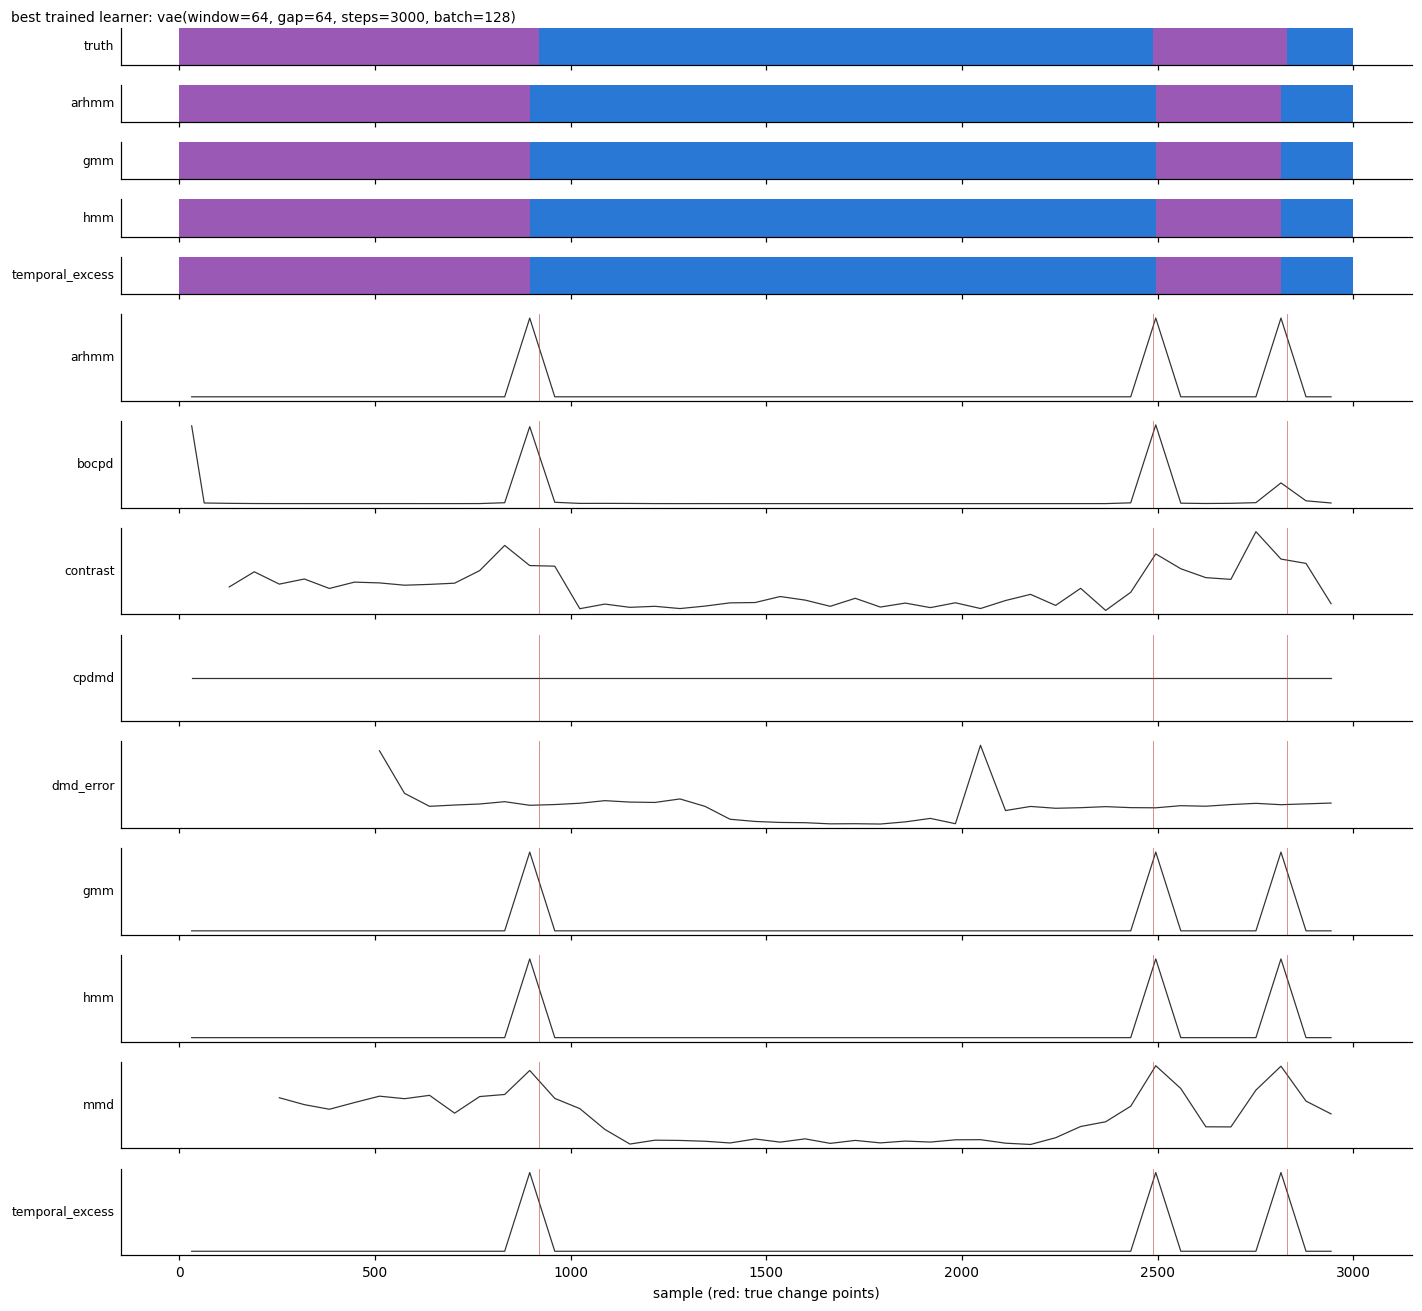

In [12]:
acc = f_[(f_.metric == "acc") & f_.features.isin([f.name for f in LEARNT])].groupby("features_label").value.max()
top = next(f for f in LEARNT if f.label() == acc.idxmax()) if len(acc) else LEARNT[0]
dec, starts = bench.decisions(top)
viz.plot_decisions(data, dec, starts, top.window, ds.K, title=f"best trained learner: {top.label()}", n=3000)

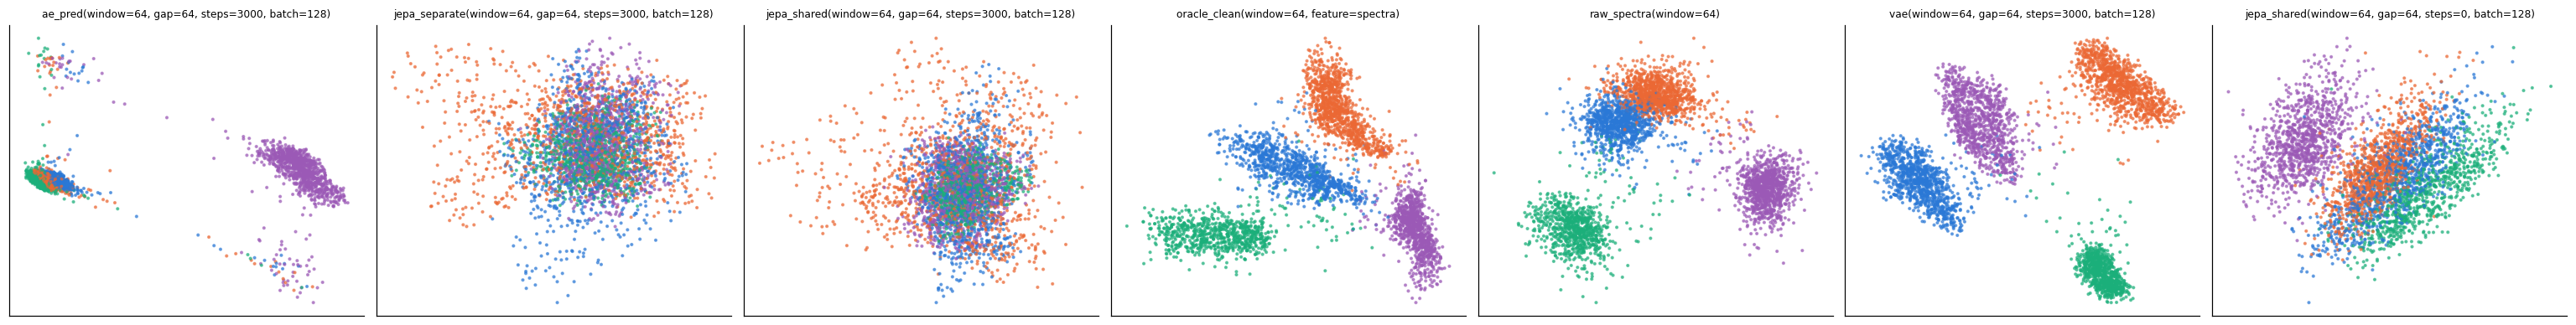

In [13]:
show = [f for f in FEATURES if f.name in ("raw_spectra", "oracle_clean", "jepa_shared", "jepa_separate", "vae", "ae_pred")]
views = {f.label(): bench.features(f)[0]["features"] for f in show}
viz.plot_features(views, data, bench.features(show[0])[1], W, ds.K)

In [14]:
# separate-design JEPAs also expose their target encoder's features: the same detectors on that view
t = res[(res.view == "target") & res.metric.isin(["acc", "cp_ap"])]
if len(t):
    display(t.pivot_table(index="features_label", columns=["metric", "detector_label"], values="value").round(3))

metric                                                          acc                                cp_ap                                                                      
detector_label                                                arhmm    gmm    hmm temporal_excess  arhmm  bocpd contrast  cpdmd dmd_error    gmm    hmm    mmd temporal_excess
features_label                                                                                                                                                                
jepa_mlp_separate(window=64, gap=64, steps=3000, batch=128)   0.943  0.966  0.972           0.974  0.433  0.075    0.014  0.017     0.021  0.765  0.765  0.062           0.870
jepa_separate(window=64, gap=64, steps=3000, batch=128)       0.952  0.967  0.971           0.975  0.561  0.045    0.014  0.012     0.023  0.793  0.789  0.058           0.861
jepa_separate_full(window=64, gap=64, steps=3000, batch=128)  0.930  0.966  0.969           0.972  0.250  0.047    0.016  0.015     0.021  0.646  0.649  0.051           0.682

## 6. Across levels

Every level whose results are on disk: the best clustering accuracy and the best change-point F1 over detectors, per feature learner. The untrained control and the raw baselines are the reference: a trained learner only helps where it beats them.

acc (best detector)


level,L0 sines,L1 triangle
learner,,
"ae(window=64, gap=64, steps=3000, batch=128)",0.973,0.973
"ae_pred(window=64, gap=64, steps=3000, batch=128)",0.712,0.961
"bvae4(window=64, gap=64, steps=3000, batch=128)",0.966,0.964
"cpc(window=64, gap=64, steps=3000, batch=128)",0.973,0.973
"jepa_mlp_separate(window=64, gap=64, steps=3000, batch=128)",0.973,0.973
"jepa_mlp_shared(window=64, gap=64, steps=3000, batch=128)",0.915,0.973
"jepa_separate(window=64, gap=64, steps=3000, batch=128)",0.973,0.974
"jepa_separate_full(window=64, gap=64, steps=3000, batch=128)",0.969,0.970
"jepa_shared(window=64, gap=64, steps=0, batch=128)",0.973,0.973


cp_f1 (best detector)


level,L0 sines,L1 triangle
learner,,
"ae(window=64, gap=64, steps=3000, batch=128)",0.835,0.806
"ae_pred(window=64, gap=64, steps=3000, batch=128)",0.464,0.659
"bvae4(window=64, gap=64, steps=3000, batch=128)",0.638,0.655
"cpc(window=64, gap=64, steps=3000, batch=128)",0.869,0.863
"jepa_mlp_separate(window=64, gap=64, steps=3000, batch=128)",0.788,0.779
"jepa_mlp_shared(window=64, gap=64, steps=3000, batch=128)",0.565,0.630
"jepa_separate(window=64, gap=64, steps=3000, batch=128)",0.858,0.865
"jepa_separate_full(window=64, gap=64, steps=3000, batch=128)",0.645,0.618
"jepa_shared(window=64, gap=64, steps=0, batch=128)",0.718,0.624


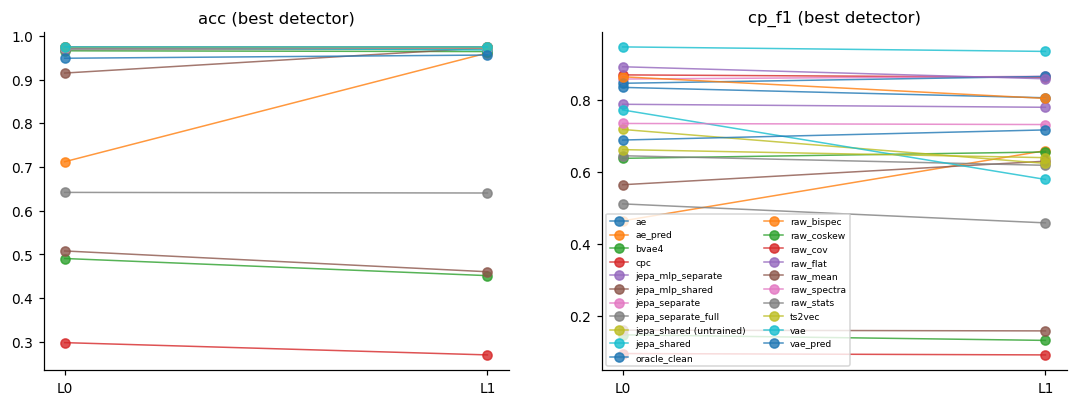

In [15]:
import glob, re
runs = {int(re.search(r"_L(\d)", p).group(1)): pd.read_csv(p) for p in sorted(glob.glob("cpbench_results/sines_L[0-9].csv"))}
rows = []
for lv, r in runs.items():
    r = r[(r.view == "features") & (r.detector != "probe")]
    for m in ("acc", "cp_f1"):
        b = r[r.metric == m].groupby("features_label").value.max()
        rows += [dict(level=LEVELS[lv], metric=m, learner=k, value=v) for k, v in b.items()]
cmp = pd.DataFrame(rows)
if len(cmp):
    for m in ("acc", "cp_f1"):
        t = cmp[cmp.metric == m].pivot_table(index="learner", columns="level", values="value")
        print(m, "(best detector)"); display(t.round(3))
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, m in zip(axes, ("acc", "cp_f1")):
        t = cmp[cmp.metric == m].pivot_table(index="learner", columns="level", values="value")
        for name, row in t.iterrows():
            ax.plot(range(t.shape[1]), row.values, marker="o", lw=1, alpha=0.8, label=name.split("(")[0] + (" (untrained)" if "steps=0" in name else ""))
        ax.set_xticks(range(t.shape[1]), [c.split()[0] for c in t.columns]); ax.set_title(m + " (best detector)")
    axes[1].legend(fontsize=6, ncol=2, loc="lower left"); plt.show()